# Import Modul


In [ ]:
!pip install visualkeras shap keras-tuner -q
!nvidia-smi

import os, warnings, cv2, shap
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import tensorflow as tf
import keras_tuner as kt
from tensorflow.keras import layers, regularizers
from tensorflow.keras.utils import plot_model
from tensorflow.keras.preprocessing.image import load_img
from sklearn.utils import class_weight
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import confusion_matrix, classification_report
import kagglehub

warnings.filterwarnings('ignore')
%matplotlib inline

print('TensorFlow version:', tf.__version__)
print('SHAP version:', shap.__version__)
print('Semua library berhasil diimport!')

Sat May 30 16:47:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   50C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Parameter Umum

In [ ]:
image_size         = 128
batch_size         = 64
projection_dim     = 64
num_heads          = 4
transformer_units  = [projection_dim * 2, projection_dim]
transformer_layers = 8
mlp_head_units     = [2048, 1024]
learning_rate      = 0.001
weight_decay       = 0.0001
np.random.seed(42)
tf.random.set_seed(42)

# Load Dataset & Data Preparation

In [ ]:
import kagglehub, os

path = kagglehub.dataset_download("oluwaseunad/concrete-and-pavement-crack-images")
print("Path dataset:", path)
folder_path = path

def load_and_process_dataset(folder_path, image_size=128):
    dataset, labels = [], []
    class_folders = ['Negative', 'Positive']
    for class_index, class_folder in enumerate(class_folders):
        images_path = os.path.join(folder_path, class_folder)
        image_names = os.listdir(images_path)
        total = len(image_names)
        for i, image_name in enumerate(image_names):
            image_path = os.path.join(images_path, image_name)
            image = cv2.imread(image_path)
            if image is None:
                continue
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = cv2.resize(image, (image_size, image_size))
            dataset.append(image)
            labels.append(class_index)
            if (i + 1) % 500 == 0:
                print(f"[{class_folder}] {i+1}/{total} gambar diproses...")
        print(f"[{class_folder}] selesai — {total} gambar")
    return np.array(dataset), np.array(labels)

dataset, lab = load_and_process_dataset(folder_path, image_size=128)
print("Shape dataset:", dataset.shape, lab.shape)

x_train, x_test, y_train, y_test = train_test_split(
    dataset, lab, test_size=0.2, shuffle=True, random_state=42
)
print(f"Train: {x_train.shape} | Test: {x_test.shape}")

Using Colab cache for faster access to the 'concrete-and-pavement-crack-images' dataset.
Path dataset: /kaggle/input/concrete-and-pavement-crack-images
[Negative] 500/15000 gambar diproses...
[Negative] 1000/15000 gambar diproses...
[Negative] 1500/15000 gambar diproses...
[Negative] 2000/15000 gambar diproses...
[Negative] 2500/15000 gambar diproses...
[Negative] 3000/15000 gambar diproses...
[Negative] 3500/15000 gambar diproses...
[Negative] 4000/15000 gambar diproses...
[Negative] 4500/15000 gambar diproses...
[Negative] 5000/15000 gambar diproses...
[Negative] 5500/15000 gambar diproses...
[Negative] 6000/15000 gambar diproses...
[Negative] 6500/15000 gambar diproses...
[Negative] 7000/15000 gambar diproses...
[Negative] 7500/15000 gambar diproses...
[Negative] 8000/15000 gambar diproses...
[Negative] 8500/15000 gambar diproses...
[Negative] 9000/15000 gambar diproses...
[Negative] 9500/15000 gambar diproses...
[Negative] 10000/15000 gambar diproses...
[Negative] 10500/15000 gamba

# Visualisasi Gambar

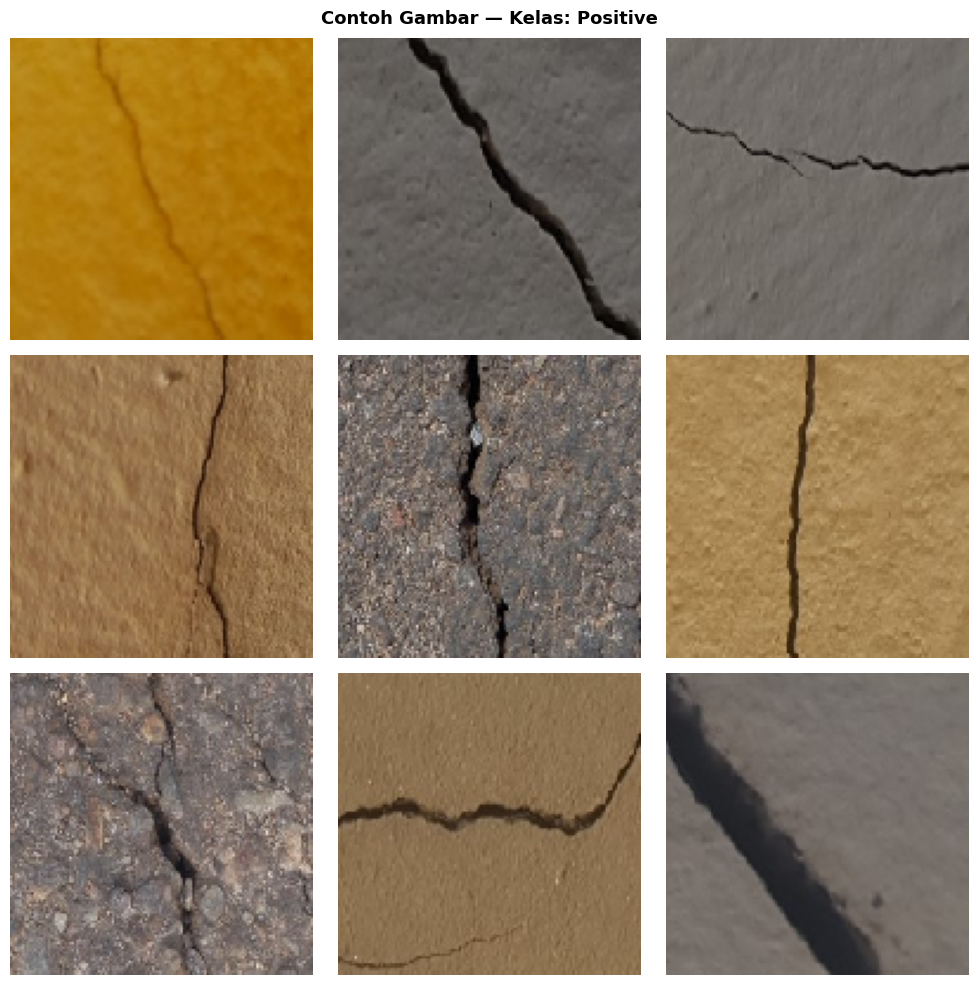

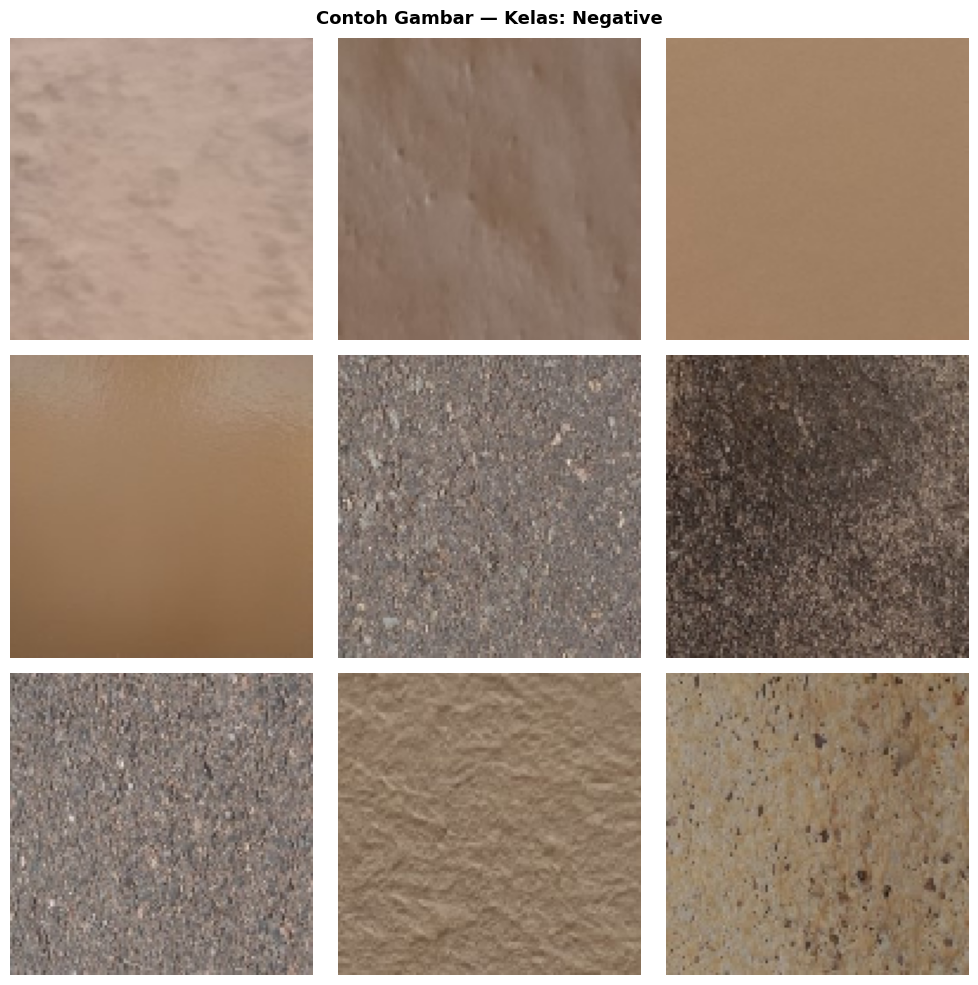

In [ ]:
def plot_state(state):
    images = [
        load_img(os.path.join(folder_path, state, img_name),
                 target_size=(image_size, image_size))
        for img_name in os.listdir(os.path.join(folder_path, state))[:9]
    ]
    fig, axes = plt.subplots(3, 3, figsize=(10, 10))
    fig.suptitle(f'Contoh Gambar — Kelas: {state}', fontsize=13, fontweight='bold')
    for ax, img in zip(axes.flat, images):
        ax.imshow(img)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

plot_state('Positive')
plot_state('Negative')

# BAGIAN 1: ANALISIS KARAKTERISTIK BIAS DAN VARIANCE



In [ ]:
# Latih CNN baseline untuk menghasilkan kurva learning awal
def build_baseline_cnn():
    model = tf.keras.Sequential([
        tf.keras.layers.Conv2D(32, (3,3), strides=(2,2), activation='relu',
                               padding='valid', input_shape=(image_size, image_size, 3)),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Conv2D(32, (3,3), strides=(2,2), activation='relu', padding='valid'),
        tf.keras.layers.MaxPooling2D((2, 2)),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation='relu',
                              kernel_regularizer=regularizers.L1L2(l1=1e-3, l2=1e-3),
                              bias_regularizer=regularizers.L2(1e-2),
                              activity_regularizer=regularizers.L2(1e-3)),
        tf.keras.layers.Dropout(0.5),
        tf.keras.layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

class_weights_dict = class_weight.compute_class_weight(
    class_weight='balanced', classes=np.unique(y_train), y=y_train
)
class_weights_dict = dict(zip(np.unique(y_train), class_weights_dict))

baseline_model   = build_baseline_cnn()
baseline_history = baseline_model.fit(
    x_train, y_train,
    epochs=30, batch_size=batch_size,
    class_weight=class_weights_dict,
    validation_data=(x_test, y_test),
    verbose=0
)
print("Baseline CNN selesai dilatih.")

Baseline CNN selesai dilatih.


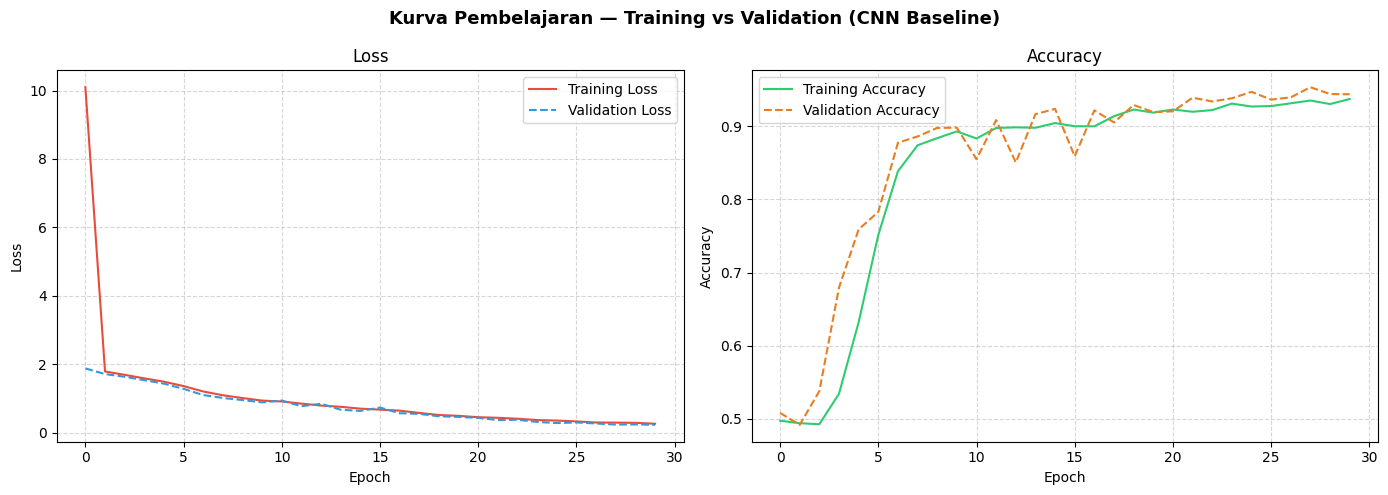


--- Analisis Bias & Variance ---
  Training   -> Loss: 0.2646, Accuracy: 0.9374
  Validation -> Loss: 0.2321,  Accuracy: 0.9438
  Gap Loss   : 0.0324 | Gap Accuracy: 0.0064

  -> Good Trade-off: Model belajar dengan baik dan generalisasi cukup baik.


In [ ]:
# Analisis Bias & Variance berdasarkan Kurva Pembelajaran ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Kurva Pembelajaran — Training vs Validation (CNN Baseline)',
             fontsize=13, fontweight='bold')

axes[0].plot(baseline_history.history['loss'],     label='Training Loss',   color='#e74c3c')
axes[0].plot(baseline_history.history['val_loss'], label='Validation Loss', color='#3498db', linestyle='--')
axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(baseline_history.history['accuracy'],     label='Training Accuracy',   color='#2ecc71')
axes[1].plot(baseline_history.history['val_accuracy'], label='Validation Accuracy', color='#e67e22', linestyle='--')
axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].legend(); axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Diagnosa Bias & Variance
final_train_loss = baseline_history.history['loss'][-1]
final_val_loss   = baseline_history.history['val_loss'][-1]
final_train_acc  = baseline_history.history['accuracy'][-1]
final_val_acc    = baseline_history.history['val_accuracy'][-1]
gap_loss         = abs(final_val_loss - final_train_loss)
gap_acc          = abs(final_train_acc - final_val_acc)

print(f'\n--- Analisis Bias & Variance ---')
print(f'  Training   -> Loss: {final_train_loss:.4f}, Accuracy: {final_train_acc:.4f}')
print(f'  Validation -> Loss: {final_val_loss:.4f},  Accuracy: {final_val_acc:.4f}')
print(f'  Gap Loss   : {gap_loss:.4f} | Gap Accuracy: {gap_acc:.4f}')

if final_train_acc < 0.80:
    print('\n  Indikator High Bias (Underfitting):')
    print('  Garis Training Loss berhenti di angka yang tinggi dan Training Accuracy rendah.')
    print('  Artinya, model bahkan tidak bisa mempelajari data latih.')
elif gap_acc > 0.10:
    print('\n  Indikator High Variance (Overfitting):')
    print('  Garis Training Loss terus turun, tetapi Validation Loss mulai naik (huruf U),')
    print('  atau terdapat gap yang sangat lebar antara akurasi latih dan validasi.')
    print('  Artinya, model terlalu menghafal data latih dan gagal mengenali data baru.')
else:
    print('\n  -> Good Trade-off: Model belajar dengan baik dan generalisasi cukup baik.')

# BAGIAN 2: DESAIN ARSITEKTUR MODEL HYBRID CNN-ViT



In [ ]:
#Komponen ViT: MLP Block
def mlp(x, hidden_units, dropout_rate):
    for units in hidden_units:
        x = layers.Dense(units, activation=tf.nn.gelu)(x)
        x = layers.Dropout(dropout_rate)(x)
    return x

# Komponen ViT: Patch Encoder
class PatchEncoder(layers.Layer):
    def __init__(self, num_patches, projection_dim):
        super().__init__()
        self.num_patches        = num_patches
        self.projection         = layers.Dense(units=projection_dim)
        self.position_embedding = layers.Embedding(
            input_dim=num_patches, output_dim=projection_dim
        )
    def call(self, patch):
        positions = tf.range(start=0, limit=self.num_patches, delta=1)
        return self.projection(patch) + self.position_embedding(positions)

# Arsitektur Hybrid CNN-ViT
def create_hybrid_cnn_vit_classifier():
    inputs = layers.Input(shape=(image_size, image_size, 3))

    # BAGIAN 1: CNN FEATURE EXTRACTOR
    x = layers.Conv2D(filters=32, kernel_size=(3,3), strides=(2,2),
                      activation="relu", padding="valid")(inputs)
    x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Conv2D(filters=64, kernel_size=(3,3), strides=(2,2),
                      activation="relu", padding="valid")(x)
    x = layers.MaxPooling2D((2, 2))(x)

    # PERHITUNGAN JUMLAH PATCH (OTOMATIS) --
    shape        = x.shape
    num_patches  = shape[1] * shape[2]  # 7 * 7 = 49
    cnn_features = shape[3]             # 64 filters/channels

    # BAGIAN 2: JEMBATAN CNN KE ViT (RESHAPE)
    reshaped_features = layers.Reshape((num_patches, cnn_features))(x)

    # Masukkan fitur yang sudah di-reshape ke PatchEncoder
    encoded_patches = PatchEncoder(num_patches, projection_dim)(reshaped_features)

    # BAGIAN 3: TRANSFORMER BLOCKS (ViT)
    for _ in range(transformer_layers):
        x1 = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
        attention_output = layers.MultiHeadAttention(
            num_heads=num_heads, key_dim=projection_dim, dropout=0.1
        )(x1, x1)
        x2 = layers.Add()([attention_output, encoded_patches])
        x3 = layers.LayerNormalization(epsilon=1e-6)(x2)
        x3 = mlp(x3, hidden_units=transformer_units, dropout_rate=0.1)
        encoded_patches = layers.Add()([x3, x2])

    # BAGIAN 4: OUTPUT KLASIFIKASI
    representation = layers.LayerNormalization(epsilon=1e-6)(encoded_patches)
    representation = layers.Flatten()(representation)
    representation = layers.Dropout(0.5)(representation)
    features       = mlp(representation, hidden_units=mlp_head_units, dropout_rate=0.5)

    # Output layer untuk 2 kelas (SparseCategoricalCrossentropy)
    logits = layers.Dense(2)(features)

    model = tf.keras.Model(inputs=inputs, outputs=logits, name="Hybrid_CNN_ViT")
    return model

# Buat model dan lihat summary-nya
hybrid_classifier = create_hybrid_cnn_vit_classifier()
hybrid_classifier.summary()

Model: "Hybrid_CNN_ViT"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 63, 63,    │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 31, 31,    │          0 │ conv2d_2[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 15, 15,    │     18,496 │ max_pooling2d_2[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 7, 7, 64)  │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 49, 64)    │          0 │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ patch_encoder       │ (None, 49, 64)    │      7,296 │ reshape[0][0]     │
│ (PatchEncoder)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 49, 64)    │        128 │ patch_encoder[0]… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 49, 64)    │     66,368 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 49, 64)    │          0 │ multi_head_atten… │
│                     │                   │            │ patch_encoder[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 49, 64)    │        128 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 49, 128)   │      8,320 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 49, 128)   │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 49, 64)    │      8,256 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 49, 64)    │          0 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 49, 64)    │          0 │ dropout_3[0][0],  │
│                     │                   │            │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 49, 64)    │        128 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 49, 64)    │     66,368 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼─────────────────

 Total params: 9,217,218 (35.16 MB)

 Trainable params: 9,217,218 (35.16 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Visualisasi arsitektur model
plot_model(hybrid_classifier, show_shapes=True, show_layer_names=False)

# BAGIAN 3: TRAINING DAN TUNING HYPERPARAMETER



In [ ]:
!pip install keras-tuner -q

# Fungsi build model untuk Keras Tuner
def build_hybrid_model(hp):
    hp_proj_dim     = hp.Choice('projection_dim',      values=[32, 64, 128])
    hp_num_heads    = hp.Choice('num_heads',            values=[2, 4, 8])
    hp_trans_layers = hp.Int('transformer_layers',      min_value=2, max_value=8, step=2)
    hp_dropout      = hp.Float('dropout_rate',          min_value=0.1, max_value=0.5, step=0.1)
    hp_lr           = hp.Choice('learning_rate',        values=[1e-3, 5e-4, 1e-4])

    inputs  = layers.Input(shape=(image_size, image_size, 3))
    x       = layers.Conv2D(32, (3,3), strides=(2,2), activation='relu', padding='valid')(inputs)
    x       = layers.MaxPooling2D((2, 2))(x)
    x       = layers.Conv2D(64, (3,3), strides=(2,2), activation='relu', padding='valid')(x)
    x       = layers.MaxPooling2D((2, 2))(x)

    shape        = x.shape
    n_patches    = shape[1] * shape[2]
    n_feat       = shape[3]
    reshaped     = layers.Reshape((n_patches, n_feat))(x)
    encoded      = PatchEncoder(n_patches, hp_proj_dim)(reshaped)

    t_units = [hp_proj_dim * 2, hp_proj_dim]
    for _ in range(hp_trans_layers):
        x1  = layers.LayerNormalization(epsilon=1e-6)(encoded)
        att = layers.MultiHeadAttention(
            num_heads=hp_num_heads, key_dim=hp_proj_dim, dropout=hp_dropout)(x1, x1)
        x2  = layers.Add()([att, encoded])
        x3  = layers.LayerNormalization(epsilon=1e-6)(x2)
        x3  = mlp(x3, hidden_units=t_units, dropout_rate=hp_dropout)
        encoded = layers.Add()([x3, x2])

    rep    = layers.LayerNormalization(epsilon=1e-6)(encoded)
    rep    = layers.Flatten()(rep)
    rep    = layers.Dropout(0.5)(rep)
    feats  = mlp(rep, hidden_units=[1024, 512], dropout_rate=0.5)
    logits = layers.Dense(2)(feats)

    model = tf.keras.Model(inputs=inputs, outputs=logits)
    model.compile(
        optimizer=tf.keras.optimizers.AdamW(learning_rate=hp_lr, weight_decay=weight_decay),
        loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
    )
    return model

# Inisialisasi Tuner
tuner = kt.RandomSearch(
    build_hybrid_model,
    objective='val_accuracy',     # Target yang ingin dimaksimalkan
    max_trials=5,                 # Jumlah maksimum kombinasi yang akan dicoba
    executions_per_trial=1,       # Berapa kali model dilatih per kombinasi
    directory='tuning_dir',       # Folder penyimpanan log
    project_name='pavement_crack_hybrid'
)

# Menampilkan ruang pencarian
tuner.search_space_summary()

Reloading Tuner from tuning_dir/pavement_crack_hybrid/tuner0.json
Search space summary
Default search space size: 5
projection_dim (Choice)
{'default': 32, 'conditions': [], 'values': [32, 64, 128], 'ordered': True}
num_heads (Choice)
{'default': 2, 'conditions': [], 'values': [2, 4, 8], 'ordered': True}
transformer_layers (Int)
{'default': None, 'conditions': [], 'min_value': 2, 'max_value': 8, 'step': 2, 'sampling': 'linear'}
dropout_rate (Float)
{'default': 0.1, 'conditions': [], 'min_value': 0.1, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.001, 'conditions': [], 'values': [0.001, 0.0005, 0.0001], 'ordered': True}


In [ ]:
# Menambahkan Early Stopping agar pelatihan berhenti jika tidak ada perbaikan
stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)

# Mulai proses Tuning
tuner.search(
    x_train, y_train,
    epochs=10,
    validation_data=(x_test, y_test),
    callbacks=[stop_early],
    batch_size=batch_size
)

# Mengambil Hyperparameter Terbaik
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("\n=== Hyperparameter Terbaik ===")
for key in ['projection_dim', 'num_heads', 'transformer_layers', 'dropout_rate', 'learning_rate']:
    print(f"  {key}: {best_hps.get(key)}")


=== Hyperparameter Terbaik ===
  projection_dim: 32
  num_heads: 8
  transformer_layers: 4
  dropout_rate: 0.5
  learning_rate: 0.001


In [ ]:
# Training Model Final dengan Hyperparameter Terbaik
best_model = tuner.hypermodel.build(best_hps)

best_history = best_model.fit(
    x_train, y_train,
    epochs=30,
    batch_size=batch_size,
    validation_data=(x_test, y_test),
    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=7, restore_best_weights=True
        )
    ],
    verbose=1
)

loss_final, acc_final = best_model.evaluate(x_test, y_test, verbose=0)
print(f'\nTest Loss     : {loss_final:.4f}')
print(f'Test Accuracy : {acc_final:.4f} ({acc_final*100:.2f}%)')

Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 47s 36ms/step - accuracy: 0.5027 - loss: 0.7702 - val_accuracy: 0.4883 - val_loss: 0.6916
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.7448 - loss: 0.4681 - val_accuracy: 0.8957 - val_loss: 0.2465
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 21ms/step - accuracy: 0.9268 - loss: 0.1886 - val_accuracy: 0.9250 - val_loss: 0.2005
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.9487 - loss: 0.1326 - val_accuracy: 0.9427 - val_loss: 0.1398
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9636 - loss: 0.0990 - val_accuracy: 0.9738 - val_loss: 0.0734
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9703 - loss: 0.0854 - val_accuracy: 0.9725 - val_loss: 0.0704
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.9738 - loss: 0.0762 - val_accuracy: 0.9747 - val_loss: 0.0697
Epoch 8/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 7s 19ms/step - accuracy: 0.9729 - loss: 0.0775 - val_ac

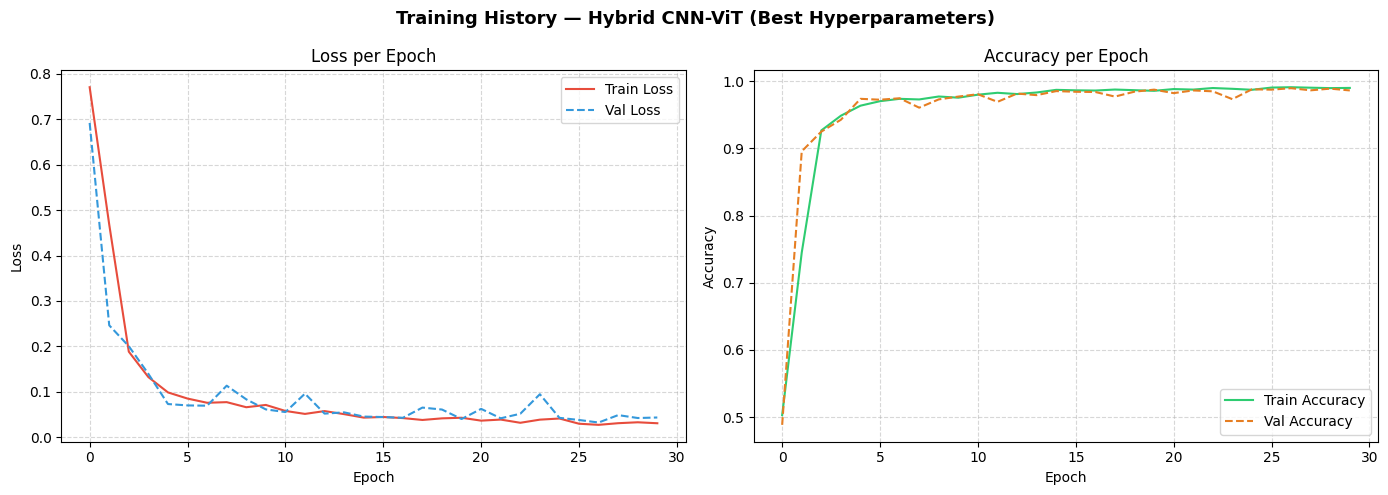

In [ ]:
# Kurva Learning Model Terbaik
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Training History — Hybrid CNN-ViT (Best Hyperparameters)',
             fontsize=13, fontweight='bold')

axes[0].plot(best_history.history['loss'],     label='Train Loss',  color='#e74c3c')
axes[0].plot(best_history.history['val_loss'], label='Val Loss',    color='#3498db', linestyle='--')
axes[0].set_title('Loss per Epoch'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].legend(); axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(best_history.history['accuracy'],     label='Train Accuracy', color='#2ecc71')
axes[1].plot(best_history.history['val_accuracy'], label='Val Accuracy',   color='#e67e22', linestyle='--')
axes[1].set_title('Accuracy per Epoch'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].legend(); axes[1].grid(True, linestyle='--', alpha=0.5)
plt.tight_layout(); plt.show()

# BAGIAN 4: VALIDASI MODEL (K-FOLD CROSS VALIDATION)



--- Evaluasi Kestabilan Model (Hyperparameter Terbaik) ---

Fold 1/5...
  Val Loss = 0.0672, Val Accuracy = 0.9775

Fold 2/5...
  Val Loss = 0.0429, Val Accuracy = 0.9860

Fold 3/5...
  Val Loss = 0.0446, Val Accuracy = 0.9865

Fold 4/5...
  Val Loss = 0.0668, Val Accuracy = 0.9777

Fold 5/5...
  Val Loss = 0.0871, Val Accuracy = 0.9680

Mean Val Loss     : 0.0617 +/- 0.0164
Mean Val Accuracy : 0.9791 +/- 0.0068
  -> Diagnosa: Model Sangat Stabil (std=0.0068)


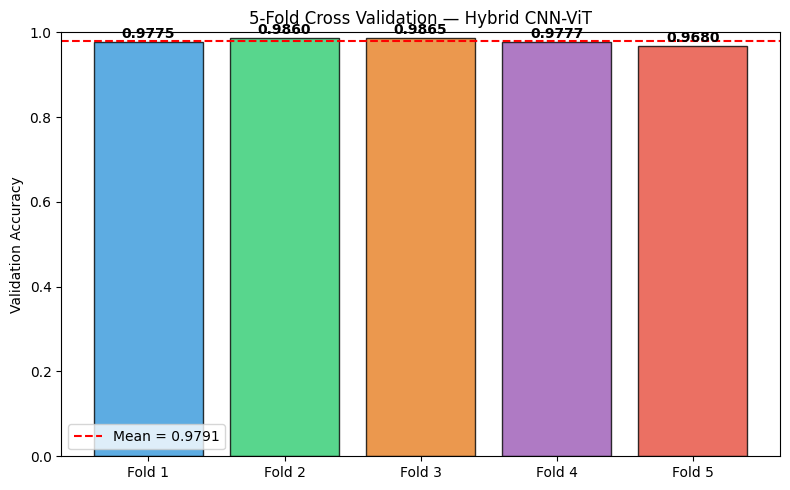

In [ ]:
# Evaluasi Kestabilan Model dengan K-Fold
print('--- Evaluasi Kestabilan Model (Hyperparameter Terbaik) ---')
N_SPLITS      = 5
skf           = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=42)
fold_losses, fold_accs = [], []

for fold_num, (train_idx, val_idx) in enumerate(skf.split(dataset, lab)):
    print(f'\nFold {fold_num+1}/{N_SPLITS}...')
    x_f_tr, x_f_val = dataset[train_idx], dataset[val_idx]
    y_f_tr, y_f_val = lab[train_idx],     lab[val_idx]

    fold_model = tuner.hypermodel.build(best_hps)
    fold_model.fit(
        x_f_tr, y_f_tr,
        epochs=15, batch_size=batch_size, verbose=0,
        validation_data=(x_f_val, y_f_val),
        callbacks=[tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=5)]
    )
    loss, acc = fold_model.evaluate(x_f_val, y_f_val, verbose=0)
    fold_losses.append(loss)
    fold_accs.append(acc)
    print(f'  Val Loss = {loss:.4f}, Val Accuracy = {acc:.4f}')

mean_acc = np.mean(fold_accs)
std_acc  = np.std(fold_accs)
print(f'\nMean Val Loss     : {np.mean(fold_losses):.4f} +/- {np.std(fold_losses):.4f}')
print(f'Mean Val Accuracy : {mean_acc:.4f} +/- {std_acc:.4f}')

if std_acc < 0.01:
    print(f'  -> Diagnosa: Model Sangat Stabil (std={std_acc:.4f})')
elif std_acc < 0.03:
    print(f'  -> Diagnosa: Model Stabil (std={std_acc:.4f})')
else:
    print(f'  -> Diagnosa: Model Kurang Stabil (std={std_acc:.4f})')

# Visualisasi K-Fold
plt.figure(figsize=(8, 5))
colors = ['#3498db','#2ecc71','#e67e22','#9b59b6','#e74c3c']
plt.bar([f'Fold {i+1}' for i in range(N_SPLITS)], fold_accs,
        color=colors, edgecolor='black', alpha=0.8)
plt.axhline(mean_acc, color='red', linestyle='--', label=f'Mean = {mean_acc:.4f}')
plt.title(f'{N_SPLITS}-Fold Cross Validation — Hybrid CNN-ViT')
plt.ylabel('Validation Accuracy'); plt.ylim(0, 1); plt.legend()
for i, v in enumerate(fold_accs):
    plt.text(i, v + 0.01, f'{v:.4f}', ha='center', fontweight='bold')
plt.tight_layout(); plt.show()

              precision    recall  f1-score   support

    Negative       0.99      0.99      0.99      3048
    Positive       0.99      0.99      0.99      2952

    accuracy                           0.99      6000
   macro avg       0.99      0.99      0.99      6000
weighted avg       0.99      0.99      0.99      6000



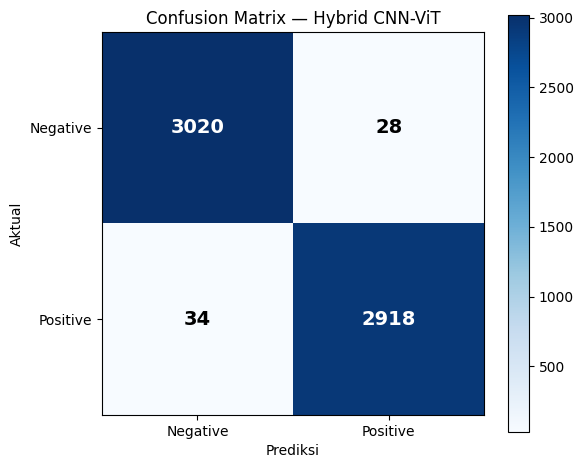

In [ ]:
# Confusion Matrix dan Classification Report
y_preds_raw = best_model.predict(x_test, verbose=0)
y_preds     = np.argmax(y_preds_raw, axis=1)

print(classification_report(y_test, y_preds, target_names=['Negative', 'Positive']))

cm = confusion_matrix(y_test, y_preds)
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues'); plt.colorbar()
plt.xticks([0, 1], ['Negative', 'Positive'])
plt.yticks([0, 1], ['Negative', 'Positive'])
plt.xlabel('Prediksi'); plt.ylabel('Aktual')
plt.title('Confusion Matrix — Hybrid CNN-ViT')
for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha='center', va='center', fontsize=14,
                 fontweight='bold',
                 color='white' if cm[i, j] > cm.max()/2 else 'black')
plt.tight_layout(); plt.show()

# BAGIAN 5: INTERPRETASI MODEL (xAI — SHAP)


In [ ]:
# SHAP via KernelExplainer
print('Menghitung SHAP values...')

x_bg      = x_train[:100].astype('float32') / 255.0
x_explain = x_test[:10].astype('float32')   / 255.0

def model_predict_fn(x):
    preds = best_model.predict(
        x.reshape(-1, image_size, image_size, 3), verbose=0
    )
    return tf.nn.softmax(preds).numpy()[:, 1]

background  = shap.sample(x_bg.reshape(100, -1), 50)
explainer   = shap.KernelExplainer(model_predict_fn, background)
shap_values = explainer.shap_values(x_explain[:5].reshape(5, -1), nsamples=100)

shap_arr = np.array(shap_values)
if shap_arr.ndim == 3:
    shap_arr = shap_arr[0]

print('SHAP selesai dihitung.')

Menghitung SHAP values...


  0%|          | 0/5 [00:00<?, ?it/s]

SHAP selesai dihitung.


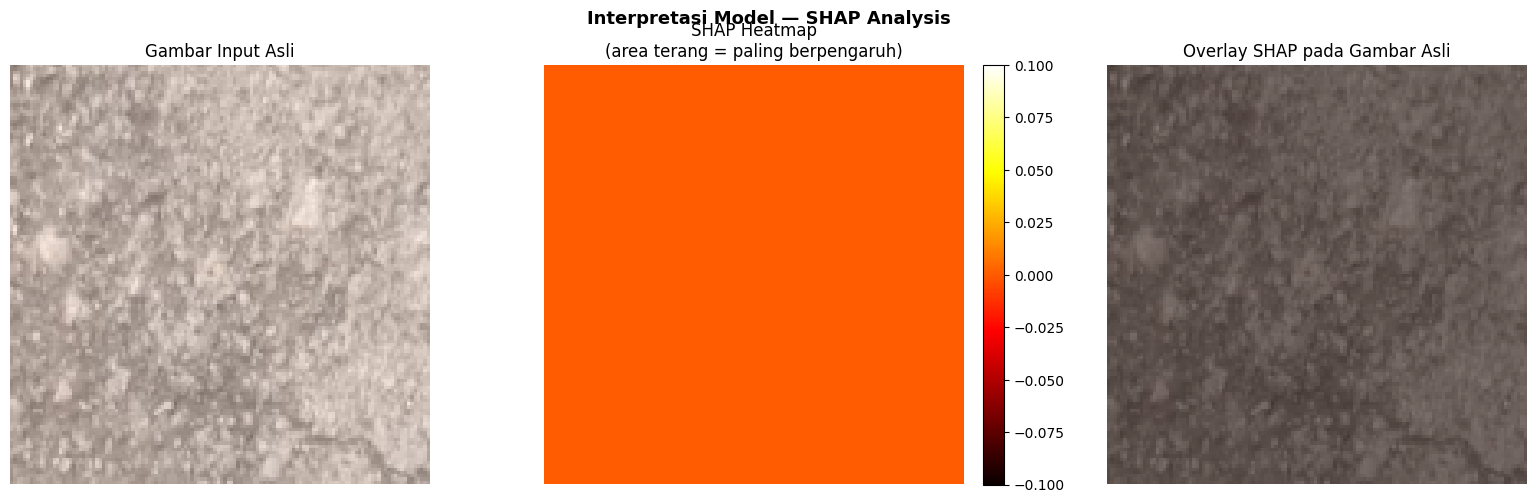

In [ ]:
# Visualisasi SHAP Heatmap
shap_abs      = np.abs(shap_arr)
mean_shap     = shap_abs.mean(axis=0)
mean_shap_img = mean_shap.reshape(image_size, image_size, 3).mean(axis=2)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('Interpretasi Model — SHAP Analysis', fontsize=13, fontweight='bold')

axes[0].imshow(x_explain[0])
axes[0].set_title('Gambar Input Asli'); axes[0].axis('off')

im = axes[1].imshow(mean_shap_img, cmap='hot', interpolation='nearest')
axes[1].set_title('SHAP Heatmap\n(area terang = paling berpengaruh)')
axes[1].axis('off')
plt.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)

axes[2].imshow(x_explain[0])
axes[2].imshow(mean_shap_img, cmap='hot', alpha=0.5, interpolation='nearest')
axes[2].set_title('Overlay SHAP pada Gambar Asli'); axes[2].axis('off')

plt.tight_layout(); plt.show()

In [ ]:
# Prediksi dan Interpretasi Sampel
pred_probs = tf.nn.softmax(best_model.predict(x_test[:5], verbose=0)).numpy()
label_map  = {0: 'Negative', 1: 'Positive'}

print('\n--- Prediksi 5 Sampel Test ---')
for i in range(5):
    pred_class = np.argmax(pred_probs[i])
    confidence = pred_probs[i][pred_class]
    true_label = label_map[y_test[i]]
    pred_label = label_map[pred_class]
    status     = '[BENAR]' if pred_class == y_test[i] else '[SALAH]'
    print(f'  Sampel {i+1}: Label Asli={true_label}, Prediksi={pred_label} '
          f'(conf={confidence:.4f}) {status}')

print('\n' + '='*55)
print('  SELESAI! Semua bagian berhasil dijalankan.')
print('='*55)


--- Prediksi 5 Sampel Test ---
  Sampel 1: Label Asli=Negative, Prediksi=Negative (conf=0.9997) [BENAR]
  Sampel 2: Label Asli=Positive, Prediksi=Positive (conf=1.0000) [BENAR]
  Sampel 3: Label Asli=Positive, Prediksi=Positive (conf=1.0000) [BENAR]
  Sampel 4: Label Asli=Positive, Prediksi=Positive (conf=1.0000) [BENAR]
  Sampel 5: Label Asli=Negative, Prediksi=Negative (conf=0.9999) [BENAR]

  SELESAI! Semua bagian berhasil dijalankan.
